# Compas Analysis

What follows are the calculations performed for ProPublica's analaysis of the COMPAS Recidivism Risk Scores. It might be helpful to open [the methodology](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm/) in another tab to understand the following.

## Loading the Data

We select fields for severity of charge, number of priors, demographics, age, sex, compas scores, and whether each person was accused of a crime within two years.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [16]:
scores_two_years = pd.read_csv("data/compas-scores-two-years.csv")

columns_to_include = [
    "id",
    "sex",
    "age",
    "age_cat",
    "race",
    "juv_fel_count",
    "decile_score",
    "juv_misd_count",
    "juv_other_count",
    "priors_count",
    "c_charge_degree",
    "c_charge_desc",
    "is_recid",
    "r_charge_degree",
    "r_charge_desc",
]

dataset = scores_two_years[columns_to_include]

n = dataset.shape[0]

main_features = ["sex", "age_cat", "race", "is_recid"]

about_main_feats = {}

for column in main_features:
    temp = pd.DataFrame()

    temp["value"] = dataset[column].unique().tolist()
    temp["count"] = dataset[column].value_counts().tolist()
    temp["percentage"] = round(
        dataset[column].value_counts(normalize=True) * 100, 1
    ).tolist()
    about_main_feats[column] = temp
    # print(f"\n\nfeature: {column}")
    # print(about_main_feats[column])

In [10]:
def plot_recid_by(
    feature: str,
    df: pd.DataFrame | None = dataset,
    label: str | None = None,
    x_order: list[str] | None = None,
    save_file: bool | None = False,
):

    order_recid = [1, 0]
    order_label = ["Yes", "No"]

    resid_plot = sns.countplot(
        df, x=feature, hue="is_recid", hue_order=order_recid, order=x_order
    )

    recid_legend = plt.legend(
        title="Recid. within\n2 years",
        loc="upper right",
        labels=order_label,
        alignment="center",
    )

    for c in resid_plot.containers:
        resid_plot.bar_label(c, fmt=lambda x: f"{(x/n)*100:0.1f}%")

    plt.setp(recid_legend.get_title(), multialignment="center")
    if not label:
        label = feature.capitalize()
    plt.xlabel(label)
    plt.ylabel("Number of defendants")
    plt.title(f"Recidivism within 2 years by {label.lower()}")
    if save_file:
        plt.savefig(f"figures/recid_by_{feature}.png", bbox_inches="tight")
    plt.show()
    plt.close()

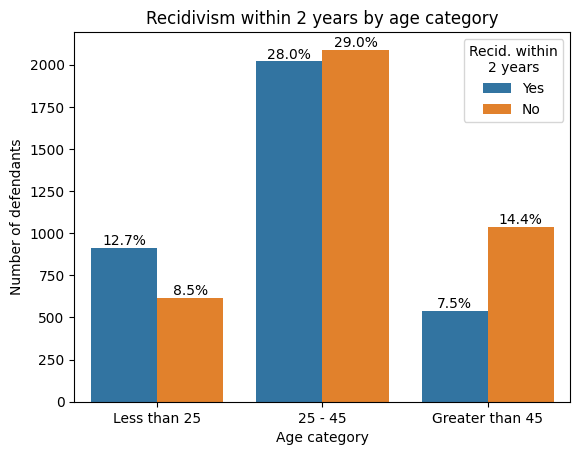

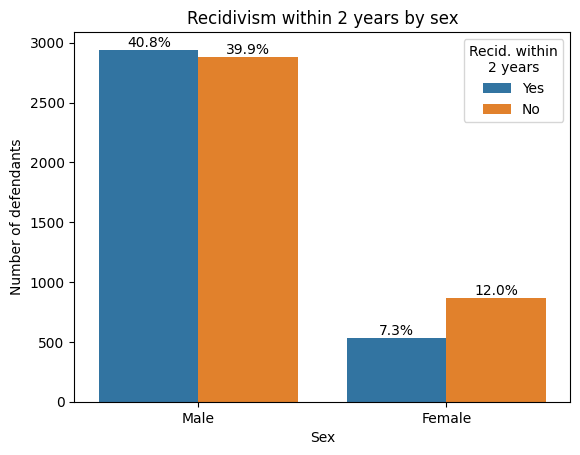

In [11]:
plot_recid_by(
    "age_cat",
    label="Age category",
    x_order=["Less than 25", "25 - 45", "Greater than 45"],
)

plot_recid_by("sex")

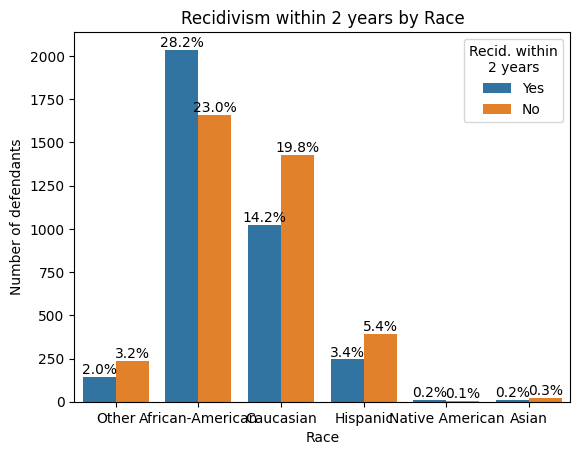

In [6]:
plot_recid_by("race")

However not all of the rows are useable for the first round of analysis.

There are a number of reasons remove rows because of missing data:
* If the charge date of a defendants Compas scored crime was not within 30 days from when the person was arrested, we assume that because of data quality reasons, that we do not have the right offense.
* We coded the recidivist flag -- `is_recid` -- to be -1 if we could not find a compas case at all.
* In a similar vein, ordinary traffic offenses -- those with a `c_charge_degree` of 'O' -- will not result in Jail time are removed (only two of them).
* We filtered the underlying data from Broward county to include only those rows representing people who had either recidivated in two years, or had at least two years outside of a correctional facility.

In [ ]:
%%R
df <- dplyr::select(raw_data, age, c_charge_degree, race, age_cat, score_text, sex, priors_count,
                    days_b_screening_arrest, decile_score, is_recid, two_year_recid, c_jail_in, c_jail_out) %>%
        filter(days_b_screening_arrest <= 30) %>%
        filter(days_b_screening_arrest >= -30) %>%
        filter(is_recid != -1) %>%
        filter(c_charge_degree != "O") %>%
        filter(score_text != 'N/A')
nrow(df)

[1] 6172


Higher COMPAS scores are slightly correlated with a longer length of stay. 

In [4]:
%%R
df$length_of_stay <- as.numeric(as.Date(df$c_jail_out) - as.Date(df$c_jail_in))
cor(df$length_of_stay, df$decile_score)

[1] 0.2073297


After filtering we have the following demographic breakdown:

In [5]:
%%R
summary(df$age_cat)

        25 - 45 Greater than 45    Less than 25 
           3532            1293            1347 


In [6]:
%%R
summary(df$race)

African-American            Asian        Caucasian         Hispanic 
            3175               31             2103              509 
 Native American            Other 
              11              343 


In [ ]:
print("Black defendants: %.2f%%" % (3175 / 6172 * 100))
print("White defendants: %.2f%%" % (2103 / 6172 * 100))
print("Hispanic defendants: %.2f%%" % (509 / 6172 * 100))
print("Asian defendants: %.2f%%" % (31 / 6172 * 100))
print("Native American defendants: %.2f%%" % (11 / 6172 * 100))

Black defendants: 51.44%
White defendants: 34.07%
Hispanic defendants: 8.25%
Asian defendants: 0.50%
Native American defendants: 0.18%


In [4]:
%%R
summary(df$score_text)

Error in df$score_text : object of type 'closure' is not subsettable


RInterpreterError: Failed to parse and evaluate line 'summary(df$score_text)\n'.
R error message: "Error in df$score_text : object of type 'closure' is not subsettable"

In [9]:
%%R
xtabs(~ sex + race, data=df)

        race
sex      African-American Asian Caucasian Hispanic Native American Other
  Female              549     2       482       82               2    58
  Male               2626    29      1621      427               9   285


In [10]:
%%R
summary(df$sex)

Female   Male 
  1175   4997 


In [ ]:
print("Men: %.2f%%" % (4997 / 6172 * 100))
print("Women: %.2f%%" % (1175 / 6172 * 100))

Men: 80.96%
Women: 19.04%


In [12]:
%%R
nrow(filter(df, two_year_recid == 1))

[1] 2809


In [13]:
%%R
nrow(filter(df, two_year_recid == 1)) / nrow(df) * 100

[1] 45.51199


Judges are often presented with two sets of scores from the Compas system -- one that classifies people into High, Medium and Low risk, and a corresponding decile score. There is a clear downward trend in the decile scores as those scores increase for white defendants.

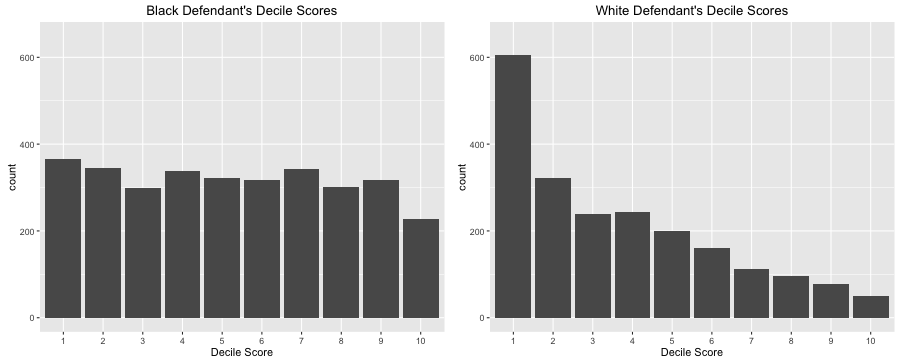

In [ ]:
%%R -w 900 -h 363 -u px
library(grid)
library(gridExtra)
pblack <- ggplot(data=filter(df, race =="African-American"), aes(ordered(decile_score))) +
          geom_bar() + xlab("Decile Score") +
          ylim(0, 650) + ggtitle("Black Defendant's Decile Scores")
pwhite <- ggplot(data=filter(df, race =="Caucasian"), aes(ordered(decile_score))) +
          geom_bar() + xlab("Decile Score") +
          ylim(0, 650) + ggtitle("White Defendant's Decile Scores")
grid.arrange(pblack, pwhite,  ncol = 2)

In [15]:
%%R
xtabs(~ decile_score + race, data=df)

            race
decile_score African-American Asian Caucasian Hispanic Native American Other
          1               365    15       605      159               0   142
          2               346     4       321       89               2    60
          3               298     5       238       73               1    32
          4               337     0       243       47               0    39
          5               323     1       200       39               0    19
          6               318     2       160       27               2    20
          7               343     1       113       28               2     9
          8               301     2        96       14               0     7
          9               317     0        77       17               2     7
          10              227     1        50       16               2     8


## Racial Bias in Compas

After filtering out bad rows, our first question is whether there is a significant difference in Compas scores between races. To do so we need to change some variables into factors, and run a logistic regression, comparing low scores to high scores.

In [16]:
%%R
df <- mutate(df, crime_factor = factor(c_charge_degree)) %>%
      mutate(age_factor = as.factor(age_cat)) %>%
      within(age_factor <- relevel(age_factor, ref = 1)) %>%
      mutate(race_factor = factor(race)) %>%
      within(race_factor <- relevel(race_factor, ref = 3)) %>%
      mutate(gender_factor = factor(sex, labels= c("Female","Male"))) %>%
      within(gender_factor <- relevel(gender_factor, ref = 2)) %>%
      mutate(score_factor = factor(score_text != "Low", labels = c("LowScore","HighScore")))
model <- glm(score_factor ~ gender_factor + age_factor + race_factor +
                            priors_count + crime_factor + two_year_recid, family="binomial", data=df)
summary(model)


Call:
glm(formula = score_factor ~ gender_factor + age_factor + race_factor + 
    priors_count + crime_factor + two_year_recid, family = "binomial", 
    data = df)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.9966  -0.7919  -0.3303   0.8121   2.6024  

Coefficients:
                            Estimate Std. Error z value Pr(>|z|)    
(Intercept)                 -1.52554    0.07851 -19.430  < 2e-16 ***
gender_factorFemale          0.22127    0.07951   2.783 0.005388 ** 
age_factorGreater than 45   -1.35563    0.09908 -13.682  < 2e-16 ***
age_factorLess than 25       1.30839    0.07593  17.232  < 2e-16 ***
race_factorAfrican-American  0.47721    0.06935   6.881 5.93e-12 ***
race_factorAsian            -0.25441    0.47821  -0.532 0.594717    
race_factorHispanic         -0.42839    0.12813  -3.344 0.000827 ***
race_factorNative American   1.39421    0.76612   1.820 0.068784 .  
race_factorOther            -0.82635    0.16208  -5.098 3.43e-07 ***
priors_count  

Black defendants are 45% more likely than white defendants to receive a higher score correcting for the seriousness of their crime, previous arrests, and future criminal behavior.

In [17]:
%%R
control <- exp(-1.52554) / (1 + exp(-1.52554))
exp(0.47721) / (1 - control + (control * exp(0.47721)))

[1] 1.452841


Women are 19.4% more likely than men to get a higher score.

In [18]:
%%R
exp(0.22127) / (1 - control + (control * exp(0.22127)))

[1] 1.194798


Most surprisingly, people under 25 are 2.5 times as likely to get a higher score as middle aged defendants.

In [19]:
%%R
exp(1.30839) / (1 - control + (control * exp(1.30839)))

[1] 2.49612


### Risk of Violent Recidivism

Compas also offers a score that aims to measure a persons risk of violent recidivism, which has a similar overall accuracy to the Recidivism score. As before, we can use a logistic regression to test for racial bias.

In [ ]:
%%R
raw_data <- read.csv("./data/compas-scores-two-years-violent.csv")
nrow(raw_data)

[1] 4743


In [ ]:
%%R
df <- dplyr::select(raw_data, age, c_charge_degree, race, age_cat, v_score_text, sex, priors_count,
                    days_b_screening_arrest, v_decile_score, is_recid, two_year_recid) %>%
        filter(days_b_screening_arrest <= 30) %>%
        filter(days_b_screening_arrest >= -30) %>%
        filter(is_recid != -1) %>%
        filter(c_charge_degree != "O") %>%
        filter(v_score_text != 'N/A')
nrow(df)

[1] 4020


In [22]:
%%R
summary(df$age_cat)

        25 - 45 Greater than 45    Less than 25 
           2300             954             766 


In [23]:
%%R
summary(df$race)

African-American            Asian        Caucasian         Hispanic 
            1918               26             1459              355 
 Native American            Other 
               7              255 


In [24]:
%%R
summary(df$v_score_text)

  High    Low Medium 
   279   2913    828 


In [25]:
%%R
nrow(filter(df, two_year_recid == 1)) / nrow(df) * 100

[1] 16.21891


In [26]:
%%R
nrow(filter(df, two_year_recid == 1))

[1] 652


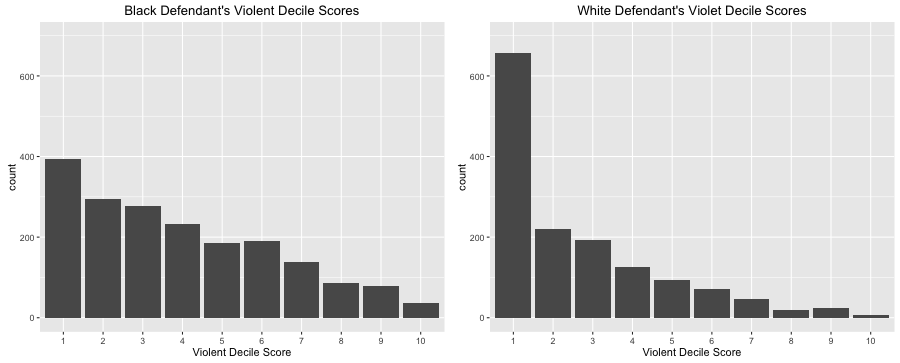

In [ ]:
%%R -w 900 -h 363 -u px
library(grid)
library(gridExtra)
pblack <- ggplot(data=filter(df, race =="African-American"), aes(ordered(v_decile_score))) +
          geom_bar() + xlab("Violent Decile Score") +
          ylim(0, 700) + ggtitle("Black Defendant's Violent Decile Scores")
pwhite <- ggplot(data=filter(df, race =="Caucasian"), aes(ordered(v_decile_score))) +
          geom_bar() + xlab("Violent Decile Score") +
          ylim(0, 700) + ggtitle("White Defendant's Violent Decile Scores")
grid.arrange(pblack, pwhite,  ncol = 2)

In [ ]:
%%R
df <- mutate(df, crime_factor = factor(c_charge_degree)) %>%
      mutate(age_factor = as.factor(age_cat)) %>%
      within(age_factor <- relevel(age_factor, ref = 1)) %>%
      mutate(race_factor = factor(race,
                                  labels = c("African-American",
                                             "Asian",
                                             "Caucasian",
                                             "Hispanic",
                                             "Native American",
                                             "Other"))) %>%
      within(race_factor <- relevel(race_factor, ref = 3)) %>%
      mutate(gender_factor = factor(sex, labels= c("Female","Male"))) %>%
      within(gender_factor <- relevel(gender_factor, ref = 2)) %>%
      mutate(score_factor = factor(v_score_text != "Low", labels = c("LowScore","HighScore")))
model <- glm(score_factor ~ gender_factor + age_factor + race_factor +
                            priors_count + crime_factor + two_year_recid, family="binomial", data=df)
summary(model)


Call:
glm(formula = score_factor ~ gender_factor + age_factor + race_factor + 
    priors_count + crime_factor + two_year_recid, family = "binomial", 
    data = df)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.9304  -0.5667  -0.3161   0.4192   2.8386  

Coefficients:
                            Estimate Std. Error z value Pr(>|z|)    
(Intercept)                 -2.24274    0.11326 -19.802  < 2e-16 ***
gender_factorFemale         -0.72890    0.12666  -5.755 8.66e-09 ***
age_factorGreater than 45   -1.74208    0.18415  -9.460  < 2e-16 ***
age_factorLess than 25       3.14591    0.11541  27.259  < 2e-16 ***
race_factorAfrican-American  0.65893    0.10815   6.093 1.11e-09 ***
race_factorAsian            -0.98521    0.70537  -1.397   0.1625    
race_factorHispanic         -0.06416    0.19133  -0.335   0.7374    
race_factorNative American   0.44793    1.03546   0.433   0.6653    
race_factorOther            -0.20543    0.22464  -0.914   0.3605    
priors_count  

The violent score overpredicts recidivism for black defendants by 77.3% compared to white defendants.

In [29]:
%%R
control <- exp(-2.24274) / (1 + exp(-2.24274))
exp(0.65893) / (1 - control + (control * exp(0.65893)))

[1] 1.773921


Defendands under 25 are 7.4 times as likely to get a higher score as middle aged defendants.

In [30]:
%%R
exp(3.14591) / (1 - control + (control * exp(3.14591)))

[1] 7.41424


## Predictive Accuracy of COMPAS

In order to test whether Compas scores do an accurate job of deciding whether an offender is Low, Medium or High risk,  we ran a Cox Proportional Hazards model. Northpointe, the company that created COMPAS and markets it to Law Enforcement, also ran a Cox model in their [validation study](http://cjb.sagepub.com/content/36/1/21.abstract).

We used the counting model and removed people when they were incarcerated. Due to errors in the underlying jail data, we need to filter out 32 rows that have an end date more than the start date. Considering that there are 13,334 total rows in the data, such a small amount of errors will not affect the results.

In [ ]:
%%R
library(survival)
library(ggfortify)

data <- filter(filter(read.csv("./data/cox-parsed.csv"), score_text != "N/A"), end > start) %>%
        mutate(race_factor = factor(race,
                                  labels = c("African-American",
                                             "Asian",
                                             "Caucasian",
                                             "Hispanic",
                                             "Native American",
                                             "Other"))) %>%
        within(race_factor <- relevel(race_factor, ref = 3)) %>%
        mutate(score_factor = factor(score_text)) %>%
        within(score_factor <- relevel(score_factor, ref=2))

grp <- data[!duplicated(data$id),]
nrow(grp)

[1] 10314


In [32]:
%%R
summary(grp$score_factor)

   Low   High Medium 
  5751   1952   2611 


In [33]:
%%R
summary(grp$race_factor)

       Caucasian African-American            Asian         Hispanic 
            3569             5147               51              944 
 Native American            Other 
              32              571 


In [34]:
%%R
f <- Surv(start, end, event, type="counting") ~ score_factor
model <- coxph(f, data=data)
summary(model)

Call:
coxph(formula = f, data = data)

  n= 13344, number of events= 3469 

                      coef exp(coef) se(coef)     z Pr(>|z|)    
score_factorHigh   1.24969   3.48927  0.04146 30.14   <2e-16 ***
score_factorMedium 0.79627   2.21725  0.04077 19.53   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       3.489     0.2866     3.217     3.785
score_factorMedium     2.217     0.4510     2.047     2.402

Concordance= 0.636  (se = 0.004 )
Rsquare= 0.068   (max possible= 0.99 )
Likelihood ratio test= 942.8  on 2 df,   p=0
Wald test            = 954.8  on 2 df,   p=0
Score (logrank) test = 1055  on 2 df,   p=0



People placed in the High category are 3.5 times as likely to recidivate, and the COMPAS system's concordance 63.6%. This is lower than the accuracy quoted in the Northpoint study of 68%.

In [35]:
%%R
decile_f <- Surv(start, end, event, type="counting") ~ decile_score
dmodel <- coxph(decile_f, data=data)
summary(dmodel)

Call:
coxph(formula = decile_f, data = data)

  n= 13344, number of events= 3469 

                 coef exp(coef) se(coef)     z Pr(>|z|)    
decile_score 0.194931  1.215228 0.005801 33.61   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

             exp(coef) exp(-coef) lower .95 upper .95
decile_score     1.215     0.8229     1.201     1.229

Concordance= 0.664  (se = 0.005 )
Rsquare= 0.08   (max possible= 0.99 )
Likelihood ratio test= 1112  on 1 df,   p=0
Wald test            = 1129  on 1 df,   p=0
Score (logrank) test = 1208  on 1 df,   p=0



COMPAS's decile scores are a bit more accurate at 66%.

We can test if the algorithm is behaving differently across races by including a race interaction term in the cox model.

In [36]:
%%R
f2 <- Surv(start, end, event, type="counting") ~ race_factor + score_factor + race_factor * score_factor
model <- coxph(f2, data=data)
print(summary(model))

Call:
coxph(formula = f2, data = data)

  n= 13344, number of events= 3469 

                                                   coef exp(coef) se(coef)
race_factorAfrican-American                     0.27879   1.32154  0.06080
race_factorAsian                               -0.77694   0.45981  0.50200
race_factorHispanic                            -0.06352   0.93846  0.09673
race_factorNative American                     -1.25468   0.28517  1.00100
race_factorOther                                0.01419   1.01429  0.11049
score_factorHigh                                1.28350   3.60927  0.08357
score_factorMedium                              0.84286   2.32301  0.07142
race_factorAfrican-American:score_factorHigh   -0.18976   0.82716  0.09985
race_factorAsian:score_factorHigh               1.31556   3.72684  0.76835
race_factorHispanic:score_factorHigh           -0.11913   0.88769  0.19833
race_factorNative American:score_factorHigh     1.95571   7.06896  1.08336
race_factorOther:score_

The interaction term shows a similar disparity as the logistic regression above.

High risk white defendants are 3.61 more likely than low risk white defendants, while High risk black defendants are 2.99 more likely than low.

In [ ]:
import math

print("Black High Hazard: %.2f" % (math.exp(-0.18976 + 1.28350)))
print("White High Hazard: %.2f" % (math.exp(1.28350)))
print("Black Medium Hazard: %.2f" % (math.exp(0.84286 - 0.17261)))
print("White Medium Hazard: %.2f" % (math.exp(0.84286)))

Black High Hazard: 2.99
White High Hazard: 3.61
Black Medium Hazard: 1.95
White Medium Hazard: 2.32


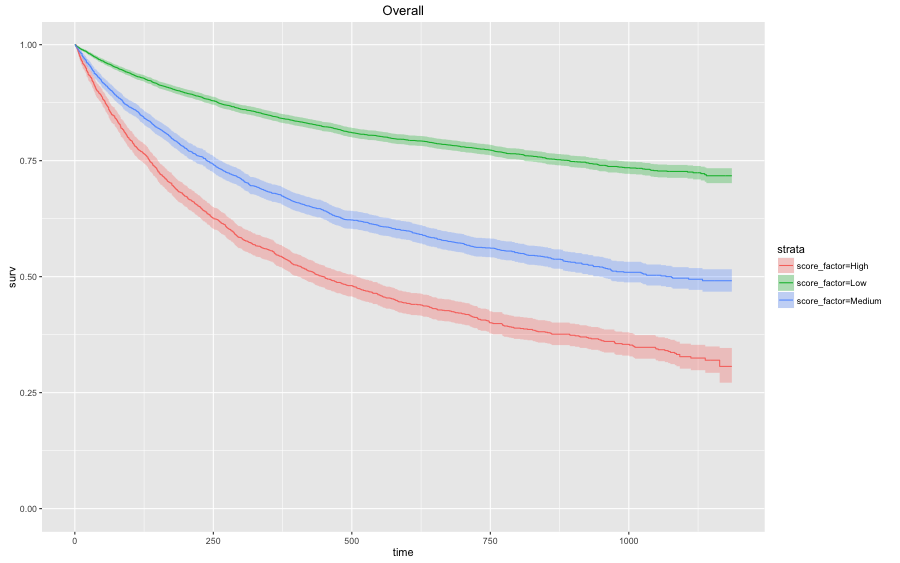

In [38]:
%%R -w 900 -h 563 -u px

fit <- survfit(f, data=data)

plotty <- function(fit, title) {
  return(autoplot(fit, conf.int=T, censor=F) + ggtitle(title) + ylim(0,1))
}
plotty(fit, "Overall")

Black defendants do recidivate at higher rates according to race specific Kaplan Meier plots.

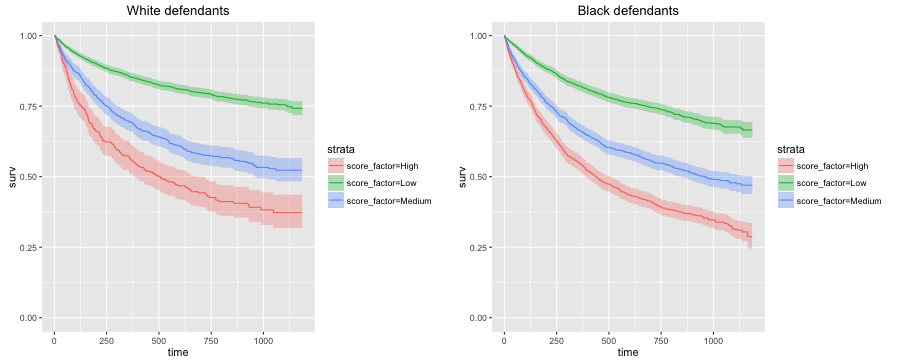

In [ ]:
%%R -w 900 -h 363 -u px
white <- filter(data, race == "Caucasian")
white_fit <- survfit(f, data=white)

black <- filter(data, race == "African-American")
black_fit <- survfit(f, data=black)

grid.arrange(plotty(white_fit, "White defendants"),
             plotty(black_fit, "Black defendants"), ncol=2)

In [40]:
%%R
summary(fit, times=c(730))

Call: survfit(formula = f, data = data)

                score_factor=Low 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     2.75e+03     1.21e+03     6.74e+03     2.79e+03     7.76e-01 
     std.err lower 95% CI upper 95% CI 
    5.74e-03     7.64e-01     7.87e-01 

                score_factor=High 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     5.05e+02     9.72e+02     6.73e+03     1.26e+03     4.08e-01 
     std.err lower 95% CI upper 95% CI 
    1.22e-02     3.85e-01     4.33e-01 

                score_factor=Medium 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     9.79e+02     1.02e+03     6.74e+03     1.39e+03     5.63e-01 
     std.err lower 95% CI upper 95% CI 
    1.03e-02     5.43e-01     5.84e-01 



In [41]:
%%R
summary(black_fit, times=c(730))

Call: survfit(formula = f, data = black)

                score_factor=Low 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     1.02e+03     5.29e+02     2.59e+03     1.04e+03     7.43e-01 
     std.err lower 95% CI upper 95% CI 
    9.70e-03     7.24e-01     7.62e-01 

                score_factor=High 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     3.62e+02     7.19e+02     2.59e+03     9.14e+02     3.98e-01 
     std.err lower 95% CI upper 95% CI 
    1.42e-02     3.71e-01     4.26e-01 

                score_factor=Medium 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     5.78e+02     6.23e+02     2.59e+03     7.85e+02     5.48e-01 
     std.err lower 95% CI upper 95% CI 
    1.34e-02     5.23e-01     5.75e-01 



In [42]:
%%R
summary(white_fit, times=c(730))

Call: survfit(formula = f, data = white)

                score_factor=Low 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     1.16e+03     4.57e+02     2.80e+03     1.18e+03     7.95e-01 
     std.err lower 95% CI upper 95% CI 
    8.63e-03     7.78e-01     8.12e-01 

                score_factor=High 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     1.02e+02     1.91e+02     2.69e+03     2.78e+02     4.35e-01 
     std.err lower 95% CI upper 95% CI 
    2.72e-02     3.85e-01     4.91e-01 

                score_factor=Medium 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     2.99e+02     3.06e+02     2.76e+03     4.60e+02     5.76e-01 
     std.err lower 95% CI upper 95% CI 
    1.85e-02     5.41e-01     6.13e-01 



Race specific models have similar concordance values.

In [43]:
%%R
summary(coxph(f, data=white))

Call:
coxph(formula = f, data = white)

  n= 4564, number of events= 1023 

                      coef exp(coef) se(coef)     z Pr(>|z|)    
score_factorHigh   1.27628   3.58327  0.08365 15.26   <2e-16 ***
score_factorMedium 0.83965   2.31556  0.07144 11.75   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       3.583     0.2791     3.041     4.222
score_factorMedium     2.316     0.4319     2.013     2.664

Concordance= 0.625  (se = 0.007 )
Rsquare= 0.056   (max possible= 0.971 )
Likelihood ratio test= 262.8  on 2 df,   p=0
Wald test            = 282.2  on 2 df,   p=0
Score (logrank) test = 311.7  on 2 df,   p=0



In [44]:
%%R
summary(coxph(f, data=black))

Call:
coxph(formula = f, data = black)

  n= 6862, number of events= 2035 

                      coef exp(coef) se(coef)     z Pr(>|z|)    
score_factorHigh   1.09514   2.98959  0.05475 20.00   <2e-16 ***
score_factorMedium 0.67025   1.95473  0.05636 11.89   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       2.990     0.3345     2.685     3.328
score_factorMedium     1.955     0.5116     1.750     2.183

Concordance= 0.623  (se = 0.006 )
Rsquare= 0.059   (max possible= 0.992 )
Likelihood ratio test= 416.9  on 2 df,   p=0
Wald test            = 401.3  on 2 df,   p=0
Score (logrank) test = 432.9  on 2 df,   p=0



Compas's violent recidivism score has a slightly higher overall concordance score of 65.1%.

In [ ]:
%%R
violent_data <- filter(filter(read.csv("./data/cox-violent-parsed.csv"), score_text != "N/A"), end > start) %>%
        mutate(race_factor = factor(race,
                                  labels = c("African-American",
                                             "Asian",
                                             "Caucasian",
                                             "Hispanic",
                                             "Native American",
                                             "Other"))) %>%
        within(race_factor <- relevel(race_factor, ref = 3)) %>%
        mutate(score_factor = factor(score_text)) %>%
        within(score_factor <- relevel(score_factor, ref=2))


vf <- Surv(start, end, event, type="counting") ~ score_factor
vmodel <- coxph(vf, data=violent_data)
vgrp <- violent_data[!duplicated(violent_data$id),]
print(nrow(vgrp))
summary(vmodel)

[1] 10985
Call:
coxph(formula = vf, data = violent_data)

  n= 18178, number of events= 818 

                      coef exp(coef) se(coef)      z Pr(>|z|)    
score_factorHigh   1.38311   3.98729  0.08410 16.447   <2e-16 ***
score_factorMedium 0.80350   2.23334  0.08699  9.236   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       3.987     0.2508     3.381     4.702
score_factorMedium     2.233     0.4478     1.883     2.649

Concordance= 0.651  (se = 0.009 )
Rsquare= 0.015   (max possible= 0.556 )
Likelihood ratio test= 270.6  on 2 df,   p=0
Wald test            = 272.2  on 2 df,   p=0
Score (logrank) test = 307.9  on 2 df,   p=0



In this case, there isn't a significant coefficient on African American's with High Scores.

In [46]:
%%R
vf2 <- Surv(start, end, event, type="counting") ~ race_factor + race_factor * score_factor
vmodel <- coxph(vf2, data=violent_data)
summary(vmodel)

Call:
coxph(formula = vf2, data = violent_data)

  n= 18178, number of events= 818 

                                                     coef  exp(coef)   se(coef)
race_factorAfrican-American                     1.976e-01  1.219e+00  1.321e-01
race_factorAsian                               -5.838e-01  5.577e-01  1.005e+00
race_factorHispanic                            -1.754e-01  8.391e-01  2.150e-01
race_factorNative American                     -1.304e+01  2.162e-06  7.607e+02
race_factorOther                               -4.459e-02  9.564e-01  2.433e-01
score_factorHigh                                1.250e+00  3.491e+00  1.720e-01
score_factorMedium                              6.292e-01  1.876e+00  1.583e-01
race_factorAfrican-American:score_factorHigh   -7.627e-03  9.924e-01  2.063e-01
race_factorAsian:score_factorHigh               1.552e+00  4.721e+00  1.425e+00
race_factorHispanic:score_factorHigh            1.606e-01  1.174e+00  3.969e-01
race_factorNative American:score_fa

In [47]:
%%R
summary(coxph(vf, data=filter(violent_data, race == "African-American")))

Call:
coxph(formula = vf, data = filter(violent_data, race == "African-American"))

  n= 9712, number of events= 495 

                     coef exp(coef) se(coef)      z Pr(>|z|)    
score_factorHigh   1.2412    3.4596   0.1140 10.891  < 2e-16 ***
score_factorMedium 0.7589    2.1359   0.1202  6.315 2.71e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       3.460     0.2891     2.767     4.325
score_factorMedium     2.136     0.4682     1.688     2.703

Concordance= 0.638  (se = 0.012 )
Rsquare= 0.013   (max possible= 0.571 )
Likelihood ratio test= 127.5  on 2 df,   p=0
Wald test            = 118.7  on 2 df,   p=0
Score (logrank) test = 130.9  on 2 df,   p=0



In [48]:
%%R
summary(coxph(vf, data=filter(violent_data, race == "Caucasian")))

Call:
coxph(formula = vf, data = filter(violent_data, race == "Caucasian"))

  n= 6041, number of events= 221 

                     coef exp(coef) se(coef)     z Pr(>|z|)    
score_factorHigh   1.2502    3.4909   0.1720 7.267 3.66e-13 ***
score_factorMedium 0.6310    1.8794   0.1583 3.986 6.71e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

                   exp(coef) exp(-coef) lower .95 upper .95
score_factorHigh       3.491     0.2865     2.492     4.891
score_factorMedium     1.879     0.5321     1.378     2.563

Concordance= 0.61  (se = 0.016 )
Rsquare= 0.008   (max possible= 0.444 )
Likelihood ratio test= 49.63  on 2 df,   p=1.672e-11
Wald test            = 55.48  on 2 df,   p=8.973e-13
Score (logrank) test = 61.24  on 2 df,   p=5.018e-14



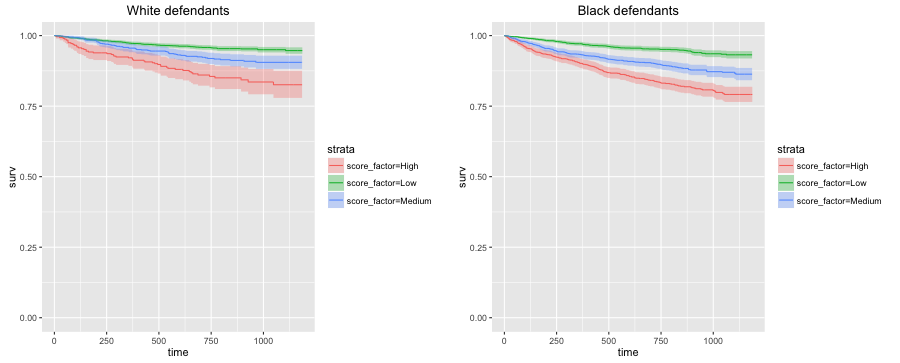

In [ ]:
%%R -w 900 -h 363 -u px
white <- filter(violent_data, race == "Caucasian")
white_fit <- survfit(vf, data=white)

black <- filter(violent_data, race == "African-American")
black_fit <- survfit(vf, data=black)

grid.arrange(plotty(white_fit, "White defendants"),
             plotty(black_fit, "Black defendants"), ncol=2)

## Directions of the Racial Bias

The above analysis shows that the Compas algorithm does overpredict African-American defendant's future recidivism, but we haven't yet explored the direction of the bias. We can discover fine differences in overprediction and underprediction by comparing Compas scores across racial lines.

In [ ]:
from truth_tables import (
    PeekyReader,
    Person,
    table,
    is_race,
    count,
    vtable,
    hightable,
    vhightable,
)
from csv import DictReader

people = []
with open("./data/cox-parsed.csv") as f:
    reader = PeekyReader(DictReader(f))
    try:
        while True:
            p = Person(reader)
            if p.valid:
                people.append(p)
    except StopIteration:
        pass

pop = list(
    filter(
        lambda i: (
            (i.recidivist == True and i.lifetime <= 730) or i.lifetime > 730
        ),
        list(filter(lambda x: x.score_valid, people)),
    )
)
recid = list(filter(lambda i: i.recidivist == True and i.lifetime <= 730, pop))
rset = set(recid)
surv = [i for i in pop if i not in rset]

In [51]:
print("All defendants")
table(list(recid), list(surv))

All defendants
           	Low	High
Survived   	2681	1282	0.55
Recidivated	1216	2035	0.45
Total: 7214.00
False positive rate: 32.35
False negative rate: 37.40
Specificity: 0.68
Sensitivity: 0.63
Prevalence: 0.45
PPV: 0.61
NPV: 0.69
LR+: 1.94
LR-: 0.55


In [52]:
print("Total pop: %i" % (2681 + 1282 + 1216 + 2035))

Total pop: 7214


In [ ]:
import statistics

print(
    "Average followup time %.2f (sd %.2f)"
    % (
        statistics.mean(map(lambda i: i.lifetime, pop)),
        statistics.stdev(map(lambda i: i.lifetime, pop)),
    )
)
print(
    "Median followup time %i"
    % (statistics.median(map(lambda i: i.lifetime, pop)))
)

Average followup time 622.87 (sd 392.19)
Median followup time 766


Overall, the false positive rate is 32.35%.

In [54]:
print("Black defendants")
is_afam = is_race("African-American")
table(list(filter(is_afam, recid)), list(filter(is_afam, surv)))

Black defendants
           	Low	High
Survived   	990	805	0.49
Recidivated	532	1369	0.51
Total: 3696.00
False positive rate: 44.85
False negative rate: 27.99
Specificity: 0.55
Sensitivity: 0.72
Prevalence: 0.51
PPV: 0.63
NPV: 0.65
LR+: 1.61
LR-: 0.51


That number is higher for African Americans at 44.85%.

In [55]:
print("White defendants")
is_white = is_race("Caucasian")
table(list(filter(is_white, recid)), list(filter(is_white, surv)))

White defendants
           	Low	High
Survived   	1139	349	0.61
Recidivated	461	505	0.39
Total: 2454.00
False positive rate: 23.45
False negative rate: 47.72
Specificity: 0.77
Sensitivity: 0.52
Prevalence: 0.39
PPV: 0.59
NPV: 0.71
LR+: 2.23
LR-: 0.62


And lower for whites at 23.45%.

In [56]:
44.85 / 23.45

1.9125799573560769

Which means under COMPAS black defendants are 91% more likely to get a higher score and not go on to commit more crimes than white defendants after two year.

COMPAS scores misclassify white reoffenders as low risk at 70.4% more often than black reoffenders.

In [57]:
47.72 / 27.99

1.7048946052161487

In [58]:
hightable(list(filter(is_white, recid)), list(filter(is_white, surv)))

           	Low	High
Survived   	1407	81	0.61
Recidivated	771	195	0.39
Total: 2454.00
False positive rate: 5.44
False negative rate: 79.81
Specificity: 0.95
Sensitivity: 0.20
Prevalence: 0.39
PPV: 0.71
NPV: 0.65
LR+: 3.71
LR-: 0.84


In [59]:
hightable(list(filter(is_afam, recid)), list(filter(is_afam, surv)))

           	Low	High
Survived   	1511	284	0.49
Recidivated	1160	741	0.51
Total: 3696.00
False positive rate: 15.82
False negative rate: 61.02
Specificity: 0.84
Sensitivity: 0.39
Prevalence: 0.51
PPV: 0.72
NPV: 0.57
LR+: 2.46
LR-: 0.72


## Risk of Violent Recidivism

Compas also offers a score that aims to measure a persons risk of violent recidivism, which has a similar overall accuracy to the Recidivism score.

In [ ]:
vpeople = []
with open("./data/cox-violent-parsed.csv") as f:
    reader = PeekyReader(DictReader(f))
    try:
        while True:
            p = Person(reader)
            if p.valid:
                vpeople.append(p)
    except StopIteration:
        pass

vpop = list(
    filter(
        lambda i: (
            (i.violent_recidivist == True and i.lifetime <= 730)
            or i.lifetime > 730
        ),
        list(filter(lambda x: x.vscore_valid, vpeople)),
    )
)
vrecid = list(
    filter(
        lambda i: i.violent_recidivist == True and i.lifetime <= 730, vpeople
    )
)
vrset = set(vrecid)
vsurv = [i for i in vpop if i not in vrset]

In [61]:
print("All defendants")
vtable(list(vrecid), list(vsurv))

All defendants
           	Low	High
Survived   	4121	1597	0.89
Recidivated	347	389	0.11
Total: 6454.00
False positive rate: 27.93
False negative rate: 47.15
Specificity: 0.72
Sensitivity: 0.53
Prevalence: 0.11
PPV: 0.20
NPV: 0.92
LR+: 1.89
LR-: 0.65


Even moreso for Black defendants.

In [62]:
print("Black defendants")
is_afam = is_race("African-American")
vtable(list(filter(is_afam, vrecid)), list(filter(is_afam, vsurv)))

Black defendants
           	Low	High
Survived   	1692	1043	0.86
Recidivated	170	273	0.14
Total: 3178.00
False positive rate: 38.14
False negative rate: 38.37
Specificity: 0.62
Sensitivity: 0.62
Prevalence: 0.14
PPV: 0.21
NPV: 0.91
LR+: 1.62
LR-: 0.62


In [63]:
print("White defendants")
is_white = is_race("Caucasian")
vtable(list(filter(is_white, vrecid)), list(filter(is_white, vsurv)))

White defendants
           	Low	High
Survived   	1679	380	0.91
Recidivated	129	77	0.09
Total: 2265.00
False positive rate: 18.46
False negative rate: 62.62
Specificity: 0.82
Sensitivity: 0.37
Prevalence: 0.09
PPV: 0.17
NPV: 0.93
LR+: 2.03
LR-: 0.77


Black defendants are twice as likely to be false positives for a Higher violent score than white defendants.

In [64]:
38.14 / 18.46

2.066088840736728

White defendants are 63% more likely to get a lower score and commit another crime than Black defendants.

In [65]:
62.62 / 38.37

1.63200416992442

## Gender differences in Compas scores

In terms of underlying recidivism rates, we can look at gender specific Kaplan Meier estimates. There is a striking difference between women and men.

In [66]:
%%R

female <- filter(data, sex == "Female")
male   <- filter(data, sex == "Male")
male_fit <- survfit(f, data=male)
female_fit <- survfit(f, data=female)

In [67]:
%%R
summary(male_fit, times=c(730))

Call: survfit(formula = f, data = male)

                score_factor=Low 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     2.13e+03     1.02e+03     5.32e+03     2.18e+03     7.58e-01 
     std.err lower 95% CI upper 95% CI 
    6.67e-03     7.45e-01     7.71e-01 

                score_factor=High 
        time       n.risk      n.event      entered     censored     survival 
     730.000      421.000      857.000     5307.000     1047.000        0.388 
     std.err lower 95% CI upper 95% CI 
       0.013        0.363        0.414 

                score_factor=Medium 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     7.52e+02     8.38e+02     5.31e+03     1.06e+03     5.35e-01 
     std.err lower 95% CI upper 95% CI 
    1.18e-02     5.13e-01     5.59e-01 



In [68]:
%%R
summary(female_fit, times=c(730))

Call: survfit(formula = f, data = female)

                score_factor=Low 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     6.17e+02     1.94e+02     1.42e+03     6.14e+02     8.38e-01 
     std.err lower 95% CI upper 95% CI 
    1.07e-02     8.17e-01     8.59e-01 

                score_factor=High 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     8.40e+01     1.15e+02     1.39e+03     2.09e+02     5.25e-01 
     std.err lower 95% CI upper 95% CI 
    3.25e-02     4.65e-01     5.93e-01 

                score_factor=Medium 
        time       n.risk      n.event      entered     censored     survival 
    7.30e+02     2.27e+02     1.84e+02     1.41e+03     3.33e+02     6.59e-01 
     std.err lower 95% CI upper 95% CI 
    2.06e-02     6.19e-01     7.00e-01 



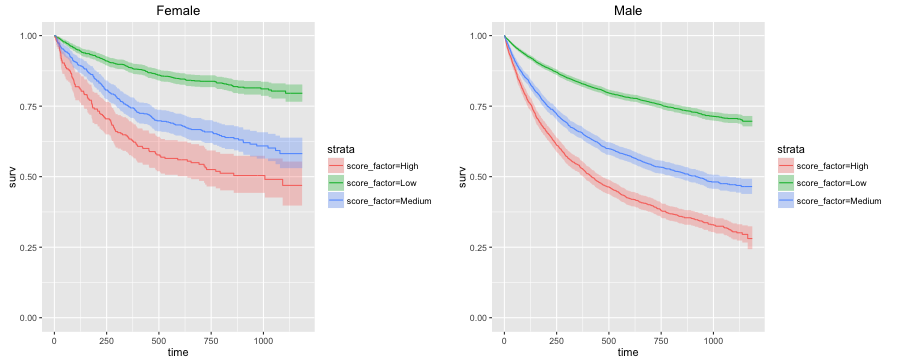

In [69]:
%%R -w 900 -h 363 -u px
grid.arrange(plotty(female_fit, "Female"), plotty(male_fit, "Male"),ncol=2)

As these plots show, the Compas score treats a High risk women the same as a Medium risk man.